In [1]:
import pandas as pd
import matplotlib.pyplot as plt

date_cols = ["applied_date", "documents_received_date", "interviewed_date", "offer_made_date",
             "training_completed_date", "induction_attended_date",
             "shadowing_completed_date", "started_date"]

df = pd.read_csv("data/recruitment_clean.csv", parse_dates=date_cols)
df.shape

(1200, 11)

In [2]:
stages = [col.replace("_date", "") for col in date_cols]
counts = [df[col].notna().sum() for col in date_cols]

funnel = pd.DataFrame({"stage": stages, "candidates": counts})
funnel["pct_of_applicants"] = (funnel["candidates"] / funnel["candidates"].iloc[0] * 100).round(1)
funnel["pct_from_previous"] = (funnel["candidates"] / funnel["candidates"].shift(1) * 100).round(1)
funnel

,stage,candidates,pct_of_applicants,pct_from_previous
0,applied,1200,100.0,NaN
1,documents_received,871,72.6,72.6
2,interviewed,569,47.4,65.3
3,offer_made,450,37.5,79.1
4,training_completed,350,29.2,77.8
5,induction_attended,323,26.9,92.3
6,shadowing_completed,291,24.2,90.1
7,started,284,23.7,97.6


In [3]:
worst = funnel.loc[funnel["pct_from_previous"].idxmin()]
print(f"Biggest drop-off: {worst['stage']} — only {worst['pct_from_previous']}% get through from the stage before")

Biggest drop-off: interviewed — only 65.3% get through from the stage before


In [4]:
by_source = df.groupby("source").agg(
    applied=("candidate_id", "count"),
    started=("started_date", "count"))
by_source["conversion_pct"] = (by_source["started"] / by_source["applied"] * 100).round(1)
by_source.sort_values("conversion_pct", ascending=False)

,applied,started,conversion_pct
source,,,
Referral,166,52,31.3
Agency,124,36,29.0
Website,179,50,27.9
Indeed,505,120,23.8
Facebook,226,26,11.5


In [5]:
starters = df[df["started_date"].notna()].copy()
starters["days_to_hire"] = (starters["started_date"] - starters["applied_date"]).dt.days
starters["days_to_hire"].describe().round(1)

count    284.0
mean      47.6
std       19.3
min       16.0
25%       34.0
50%       44.0
75%       57.0
max      134.0
Name: days_to_hire, dtype: float64

In [6]:
for before, after in zip(date_cols[:-1], date_cols[1:]):
    median_days = (df[after] - df[before]).dt.days.median()
    print(f"{after.replace('_date',''):22} {median_days} days")

documents_received     2.0 days
interviewed            3.0 days
offer_made             1.0 days
training_completed     11.0 days
induction_attended     3.0 days
shadowing_completed    15.0 days
started                2.0 days


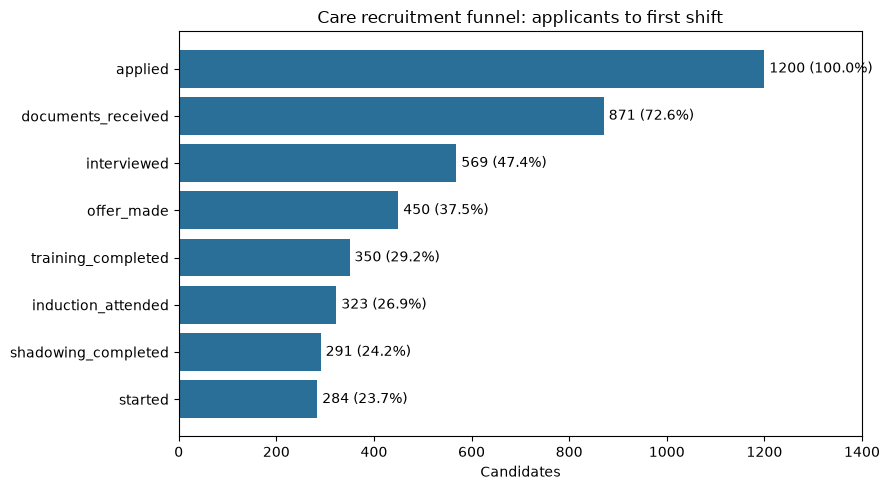

In [8]:
plt.figure(figsize=(9, 5))
plt.barh(funnel["stage"], funnel["candidates"], color="#2a6f97")
plt.gca().invert_yaxis()
for i, v in enumerate(funnel["candidates"]):
    plt.text(v + 10, i, f"{v} ({funnel['pct_of_applicants'][i]}%)", va="center")
    plt.xlim(0, 1400)
plt.title("Care recruitment funnel: applicants to first shift")
plt.xlabel("Candidates")
plt.tight_layout()
plt.savefig("funnel_chart.png", dpi=150)
plt.show()

## Key findings

1. **Only 23.7% of applicants start work** — 284 of 1,200 candidates reached their first shift, roughly 1 in 4.
2. **The interview stage is the leakiest step.** Only 65.3% of candidates who sent documents went on to be interviewed. The largest *numbers* are lost at the very start (329 applicants never sent documents), but interview scheduling has the lowest step conversion rate.
3. **Referrals convert almost 3x better than Facebook** — 31.3% of referred candidates started work, compared with 11.5% from Facebook. Indeed brings the most applicants (505) but converts at only 23.8%.
4. **Median time-to-hire is 44 days** (mean 47.6 days, pulled up by a few very slow hires). Shadowing is the slowest stage at a median of 15 days, followed by Care Certificate training at 11 days.

## Recommendations

- **Speed up interview booking** — contact candidates within 24–48 hours of receiving documents, as this is where the highest share of candidates is lost.
- **Invest in a staff referral scheme** and review Facebook advertising spend, which produces many applicants but few starters.
- **Review the shadowing period** — it takes the longest; a structured 2-week shadowing plan could cut time-to-hire without lowering standards.

*Note: data is synthetic, generated to reflect a real 8-stage care-sector recruitment process. Findings demonstrate the analysis method rather than any real organisation's performance.*